In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import warnings
from warnings import filterwarnings
filterwarnings('ignore')

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [5]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

In [6]:
# 1. LOAD DATASET
df = pd.read_csv("loan_approval_dataset.csv")
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [7]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (4269, 13)
   loan_id  no_of_dependents     education self_employed  income_annum  \
0        1                 2      Graduate            No       9600000   
1        2                 0  Not Graduate           Yes       4100000   
2        3                 3      Graduate            No       9100000   
3        4                 3      Graduate            No       8200000   
4        5                 5  Not Graduate           Yes       9800000   

   loan_amount  loan_term  cibil_score  residential_assets_value  \
0     29900000         12          778                   2400000   
1     12200000          8          417                   2700000   
2     29700000         20          506                   7100000   
3     30700000          8          467                  18200000   
4     24200000         20          382                  12400000   

   commercial_assets_value  luxury_assets_value  bank_asset_value loan_status  
0                 17600000             2

In [8]:
# Step 3: Explore the dataset
# Check missing values, duplicates, and the number of approved and rejected loans.

In [9]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Check loan status distribution
print("\nLoan Status Count:")
print(df["loan_status"].value_counts())



Missing Values:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64
Duplicate Rows: 0

Loan Status Count:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


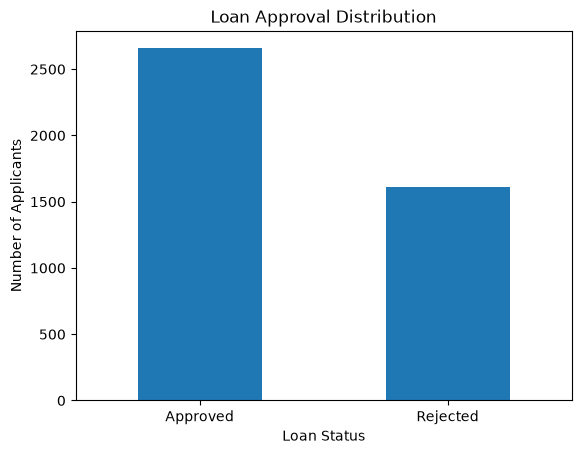

In [10]:
# Loan status chart
df["loan_status"].value_counts().plot(kind="bar")
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.show()


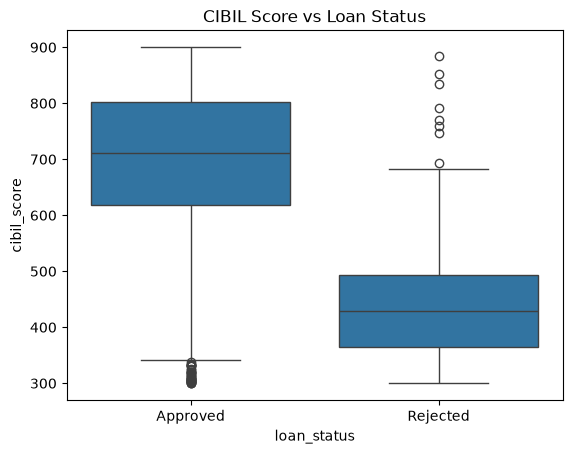

In [11]:
sns.boxplot(data=df, x="loan_status", y="cibil_score")
plt.title("CIBIL Score vs Loan Status")
plt.show()

In [12]:
# Step 4: Separate input and output

In [13]:
# Input features
X = df.drop(columns=["loan_id", "loan_status"])

# Target variable
y = df["loan_status"]

# Convert target labels into numbers
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Target Mapping:")
print(dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
)))

Target Mapping:
{'Approved': np.int64(0), 'Rejected': np.int64(1)}


In [14]:
# Step 5: Split training and testing data
# # We use 80% of the data for training and 20% for testing.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (3415, 11)
Testing Data: (854, 11)


In [16]:
# Step 6: Preprocess the data
# XGBoost needs numeric input. 
# We convert categorical columns such as education and self_employed using OneHotEncoder.

In [17]:
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = X.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("num", "passthrough", numeric_features)
])

In [18]:
# Step 7: Create the XGBoost model

In [19]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)



In [20]:
# Combine preprocessing and model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", xgb_model)
])

In [21]:
# Step 8: Train the model using model.fit()

In [22]:
# Train the model
model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [23]:
# Step 9: Calculate training and testing accuracy

In [24]:
# 9. Make Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [25]:
# 10. Training and Testing Accuracy
print("\nTraining Accuracy:",
      round(accuracy_score(y_train, y_train_pred) * 100, 2), "%")

print("Testing Accuracy:",
      round(accuracy_score(y_test, y_test_pred) * 100, 2), "%")


Training Accuracy: 99.91 %
Testing Accuracy: 98.24 %


In [26]:
# 11. Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=label_encoder.classes_,
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

    Approved       0.98      0.99      0.99       531
    Rejected       0.99      0.97      0.98       323

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854




Confusion Matrix:
[[527   4]
 [ 11 312]]


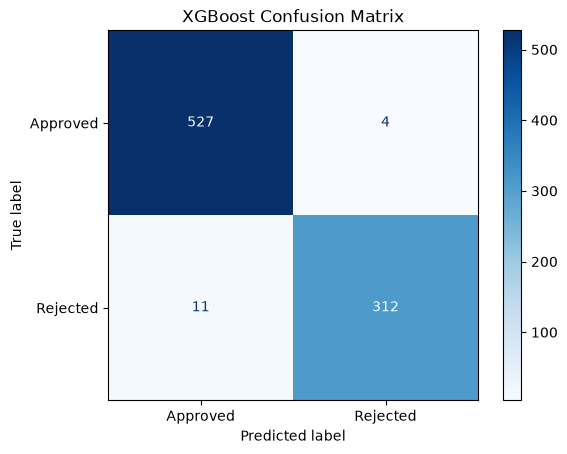

In [27]:
# 12. Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(cmap="Blues", values_format="d")

plt.title("XGBoost Confusion Matrix")
plt.show()


In [28]:
import joblib

joblib.dump(
    {
        "model": model,
        "label_encoder": label_encoder
    },
    "creditwise_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
